# Comparative Intelligence and Ethics in Machine Learning Systems

## Research Question

How do a traditional machine-learning model and a deep-learning model compare in classifying waste images, and what do their performance, explainability and robustness reveal about the ethical considerations of deploying such systems?

## Research Aim

To compare an HOG-based Support Vector Machine (SVM) and a Convolutional Neural Network (CNN) for six-class waste image classification using the TrashNet dataset, while examining class-level performance, explainability, robustness and deployment risks.

## Research Objectives

1. Prepare and explore the TrashNet image dataset.
2. Develop and evaluate an HOG-based SVM and a CNN using a consistent data split.
3. Compare model performance using accuracy, precision, recall, F1-score and confusion matrices.
4. Use Grad-CAM to investigate regions influencing CNN predictions.
5. Examine sensitivity to a brightness perturbation and identify limitations in class-level performance.
6. Discuss ethical risks, privacy, fairness limitations and recommendations for responsible deployment.

# INSTALLATIONS


In [ ]:
#%pip install datasets


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
#%pip install datasets


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
#%pip install -U ipywidgets


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
from pathlib import Path

PROJECT_DIR = Path.home() / "TrashNet_Project"
DATA_DIR = PROJECT_DIR / "data"

DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Writable:", DATA_DIR.exists())

Project directory: /Users/emilys/TrashNet_Project
Data directory: /Users/emilys/TrashNet_Project/data
Writable: True


In [6]:
from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    repo_id="garythung/trashnet",
    filename="dataset-resized.zip",
    repo_type="dataset"
)

print("Downloaded to:", zip_path)

Downloaded to: /Users/emilys/.cache/huggingface/hub/datasets--garythung--trashnet/snapshots/94cd17ebfd6702bf62281d3c89f22ff649815b46/dataset-resized.zip


In [7]:
import zipfile

extract_dir = DATA_DIR / "TrashNet"
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

print("Extracted to:", extract_dir)
print("Contents:", [p.name for p in extract_dir.iterdir()])

Extracted to: /Users/emilys/TrashNet_Project/data/TrashNet
Contents: ['__MACOSX', 'dataset-resized']


# Stage 2: Exploratory Data Analysis (EDA)

In [8]:
from pathlib import Path

PROJECT_DIR = Path.home() / "TrashNet_Project"
DATA_DIR = PROJECT_DIR / "data"
extract_dir = DATA_DIR / "TrashNet"

for path in (extract_dir / "dataset-resized").iterdir():
    print(path.name)

paper
.DS_Store
metal
cardboard
trash
glass
plastic


In [9]:
from collections import Counter

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

DATASET_ROOT = extract_dir / "dataset-resized"

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

class_counts = Counter({
    class_name: sum(
        1 for path in (DATASET_ROOT / class_name).rglob("*")
        if path.is_file()
        and path.suffix.lower() in image_extensions
    )
    for class_name in CLASSES
})

for class_name in CLASSES:
    print(f"{class_name:12s}: {class_counts[class_name]}")

print("\nTotal images:", sum(class_counts.values()))

cardboard   : 403
glass       : 501
metal       : 410
paper       : 594
plastic     : 482
trash       : 137

Total images: 2527


In [10]:
%pip install matplotlib seaborn pandas numpy scikit-learn scikit-image pillow tensorflow

  Using cached matplotlib-3.11.2-cp311-cp311-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp311-cp311-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scikit_image-0.26.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (15 kB)
  Using cached pillow-12.3.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached tensorflow-2.21.0-cp311-cp311-macosx_12_0_arm64.whl.metadata (4.4 kB)
  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp311-cp311-macosx_10_9_universal2.whl.metadata (130 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.met

Matplotlib is building the font cache; this may take a moment.


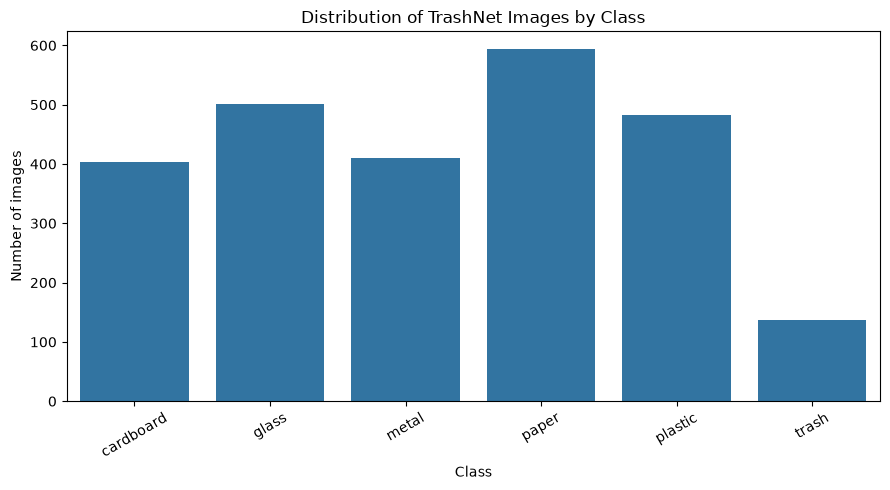

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

counts_df = pd.DataFrame({
    "Class": CLASSES,
    "Number of images": [class_counts[c] for c in CLASSES]
})

plt.figure(figsize=(9, 5))
sns.barplot(data=counts_df, x="Class", y="Number of images")
plt.title("Distribution of TrashNet Images by Class")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("All imports successful!")

Pandas: 3.0.6
Scikit-learn: 1.9.1
TensorFlow: 2.21.0
All imports successful!


In [13]:
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path.home() / "TrashNet_Project"
DATASET_ROOT = PROJECT_DIR / "data" / "TrashNet" / "dataset-resized"

CLASSES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

class_counts = Counter({
    class_name: sum(
        1 for p in (DATASET_ROOT / class_name).rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    )
    for class_name in CLASSES
})

for class_name in CLASSES:
    print(f"{class_name:12s}: {class_counts[class_name]}")

print("\nTotal images:", sum(class_counts.values()))

cardboard   : 403
glass       : 501
metal       : 410
paper       : 594
plastic     : 482
trash       : 137

Total images: 2527


# Data Preparation and Splitting 

In [15]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from pathlib import Path

# Collect image paths and labels
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_paths = []
labels = []

for class_name in CLASSES:
    class_dir = DATASET_ROOT / class_name

    for path in sorted(class_dir.rglob("*")):
        if path.is_file() and path.suffix.lower() in image_extensions:
            image_paths.append(str(path))
            labels.append(class_name)

# Create a dataframe
df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

# Check for missing files
df = df[df["image_path"].map(lambda p: Path(p).is_file())]
df = df.reset_index(drop=True)

# Split 1: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Split 2: divide temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training images: 1768
Validation images: 379
Test images: 380
Total: 2527


## Verifying the class distribution in each split

In [16]:
split_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(CLASSES)

print(split_counts)

# Confirm that no file appears in more than one split
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

print("\nNo image paths overlap across splits.")

           Train  Validation  Test
label                             
cardboard    282          61    60
glass        350          75    76
metal        287          61    62
paper        416          89    89
plastic      337          72    73
trash         96          21    20

No image paths overlap across splits.


## Preview the split

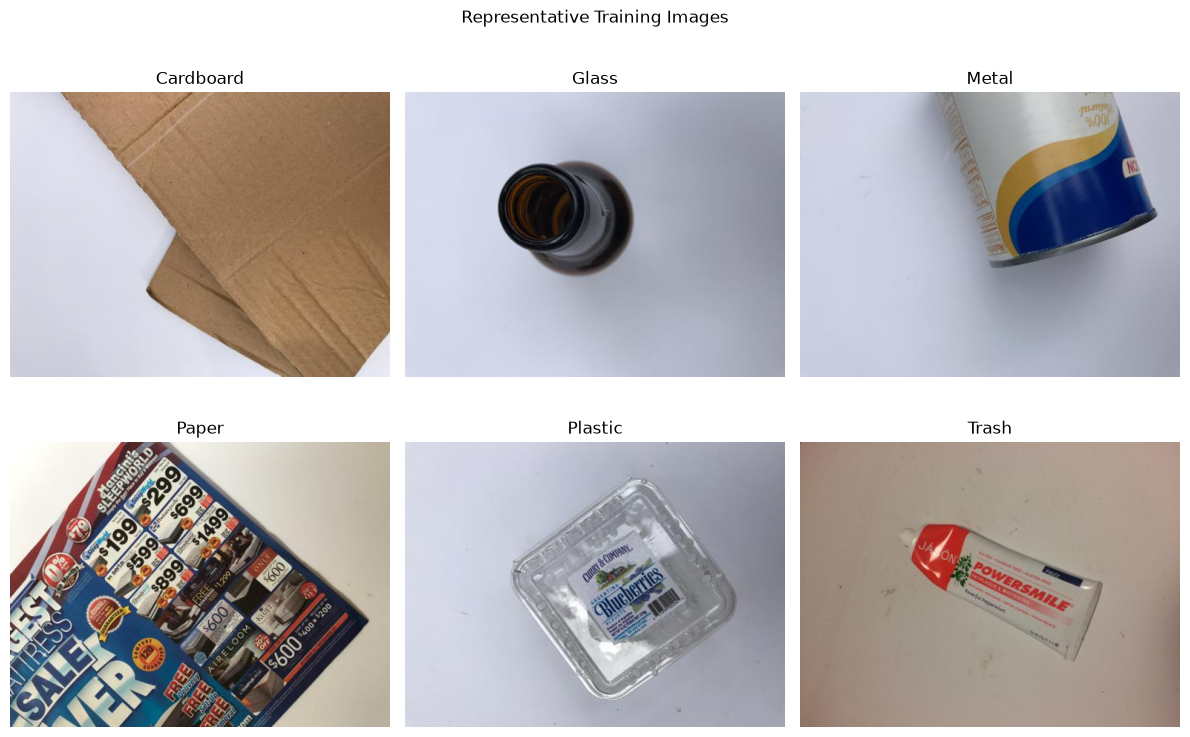

In [17]:
from PIL import Image
import matplotlib.pyplot as plt

sample_df = (
    train_df.groupby("label", group_keys=False)
    .sample(n=1, random_state=42)
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    with Image.open(row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(row["label"].capitalize())
    ax.axis("off")

plt.suptitle("Representative Training Images")
plt.tight_layout()
plt.show()

##  Image Quality and Dimensions

In [ ]:
from PIL import Image, UnidentifiedImageError
from collections import Counter

image_sizes = Counter()
corrupted_images = []
image_modes = Counter()

for path in df["image_path"]:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen after verify() before reading metadata
        with Image.open(path) as img:
            image_sizes[img.size] += 1
            image_modes[img.mode] += 1

    except (OSError, UnidentifiedImageError) as error:
        corrupted_images.append((path, str(error)))

print("Image dimensions and counts:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count}")

print("\nImage modes:", image_modes)
print("Corrupted images:", len(corrupted_images))


Image dimensions and counts:
(512, 384): 2527

Image modes: Counter({'RGB': 2527})
Corrupted images: 0


# Stage 3: Classical machine learning — HOG + SVM


### 3.1 Methodology

The classical machine learning baseline combines Histogram of Oriented
Gradients (HOG) feature extraction with a Support Vector Machine (SVM)
classifier. HOG represents local edge and shape information as numerical
features, while the SVM learns to distinguish the six waste categories.

This approach provides a useful baseline against which the performance
of a Convolutional Neural Network (CNN) can be compared.

In [19]:
# Load and resize the images

import numpy as np
from PIL import Image
from tqdm.auto import tqdm

IMG_SIZE = (96, 96)

def load_hog_images(dataframe):
    images = []
    labels = []

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc="Loading images"
    ):
        with Image.open(row["image_path"]) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)
            images.append(np.asarray(img))

        labels.append(row["label"])

    return np.asarray(images), np.asarray(labels)

X_train_img, y_train = load_hog_images(train_df)
X_val_img, y_val = load_hog_images(val_df)
X_test_img, y_test = load_hog_images(test_df)

print("Training images:", X_train_img.shape)
print("Validation images:", X_val_img.shape)
print("Test images:", X_test_img.shape)

Loading images:   0%|          | 0/1768 [00:00<?, ?it/s]

Loading images:   0%|          | 0/379 [00:00<?, ?it/s]

Loading images:   0%|          | 0/380 [00:00<?, ?it/s]

Training images: (1768, 96, 96, 3)
Validation images: (379, 96, 96, 3)
Test images: (380, 96, 96, 3)


In [ ]:
# Extract HOG features
# convert the images into numerical feature vectors.
from skimage.feature import hog

def extract_hog_features(images):
    features = []

    for image in tqdm(images, desc="Extracting HOG"):
        gray = np.asarray(
            Image.fromarray(image).convert("L")
        )

        feature_vector = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(feature_vector)

    return np.asarray(features, dtype=np.float32)

X_train_hog = extract_hog_features(X_train_img)
X_val_hog = extract_hog_features(X_val_img)
X_test_hog = extract_hog_features(X_test_img)

print("HOG training shape:", X_train_hog.shape)
print("HOG validation shape:", X_val_hog.shape)
print("HOG test shape:", X_test_hog.shape)

Extracting HOG:   0%|          | 0/1768 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/379 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/380 [00:00<?, ?it/s]

HOG training shape: (1768, 4356)
HOG validation shape: (379, 4356)
HOG test shape: (380, 4356)


In [21]:
# Train the SVM
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import f1_score

CANDIDATE_C = [1, 10, 100]
svm_results = []

for c_value in CANDIDATE_C:
    svm_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=c_value,
            class_weight="balanced"
        ))
    ])

    svm_pipeline.fit(X_train_hog, y_train)

    val_predictions = svm_pipeline.predict(X_val_hog)

    macro_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro"
    )

    svm_results.append({
        "C": c_value,
        "Validation macro-F1": macro_f1,
        "Model": svm_pipeline
    })

    print(f"C={c_value}, validation macro-F1={macro_f1:.4f}")

best_svm_result = max(
    svm_results,
    key=lambda result: result["Validation macro-F1"]
)

best_svm = best_svm_result["Model"]

print("\nSelected C:", best_svm_result["C"])
print(
    "Best validation macro-F1:",
    round(best_svm_result["Validation macro-F1"], 4)
)


C=1, validation macro-F1=0.6356
C=10, validation macro-F1=0.6430
C=100, validation macro-F1=0.6430

Selected C: 10
Best validation macro-F1: 0.643


**HOG + SVM: Hyperparameter Selection**

The RBF-kernel SVM was evaluated using three values of the regularisation parameter \(C\). The model with \(C=10\) achieved the highest validation macro-F1 score of 0.6430. The configuration with \(C=100\) achieved the same score, while \(C=1\) produced a slightly lower score of 0.6356. Therefore, \(C=10\) was selected for final evaluation.

SVM test accuracy: 0.6211

Classification report:

              precision    recall  f1-score   support

   cardboard       0.66      0.62      0.64        60
       glass       0.57      0.66      0.61        76
       metal       0.59      0.53      0.56        62
       paper       0.63      0.75      0.69        89
     plastic       0.65      0.58      0.61        73
       trash       0.78      0.35      0.48        20

    accuracy                           0.62       380
   macro avg       0.65      0.58      0.60       380
weighted avg       0.63      0.62      0.62       380



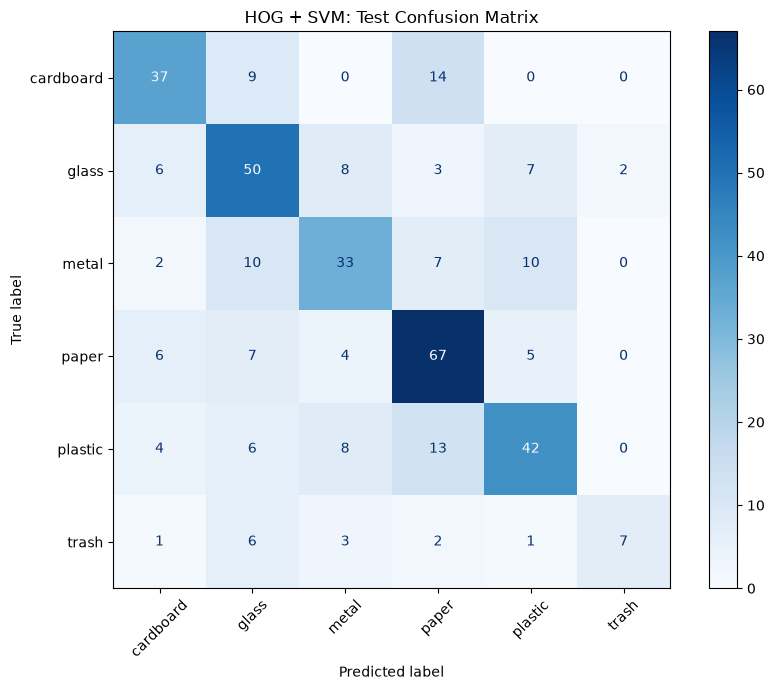

In [22]:
# Evaluate the selected SVM on the test set
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

svm_test_predictions = best_svm.predict(X_test_hog)

print("SVM test accuracy:",
      round(accuracy_score(y_test, svm_test_predictions), 4))

print("\nClassification report:\n")
print(classification_report(
    y_test,
    svm_test_predictions,
    labels=CLASSES,
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    svm_test_predictions,
    labels=CLASSES
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("HOG + SVM: Test Confusion Matrix")
plt.tight_layout()
plt.show()

**HOG + SVM: Test Results and Diagnostic Analysis**

The HOG + SVM classifier achieved a test accuracy of 62.11% and a macro-F1 score of approximately 0.60. Among the six waste categories, paper achieved the highest recall (0.75), while trash achieved the lowest recall (0.35).

The low recall for trash indicates that the model failed to identify 13 of the 20 actual trash images. This may reflect the limited number of training examples for this class, visual similarities between waste categories, or limitations of handcrafted HOG features.

These findings demonstrate why overall accuracy alone is insufficient for evaluating a waste-classification model. Per-class metrics are necessary to identify categories for which classification errors may have greater operational consequences. The CNN will be evaluated using the same held-out test set to determine whether automatically learned image features improve classification performance.

# 4. Deep Learning: Convolutional Neural Network (CNN)

### Model Selection and Rationale

A Convolutional Neural Network (CNN) was selected as the deep learning approach because CNNs are designed to learn spatial patterns and visual features directly from images. Unlike the traditional HOG-SVM model, which relies on manually extracted Histogram of Oriented Gradients features, the CNN learns relevant features during training. This makes it suitable for investigating whether automatic feature learning improves waste image classification.

### Image Preprocessing

All images were resized to 96 × 96 pixels and represented as RGB images to ensure a consistent input size. The images were converted into numerical arrays for processing by TensorFlow and Keras. Pixel values were rescaled to the range 0–1 using a rescaling layer with a factor of 1/255.

The dataset was divided into stratified training, validation, and test sets, containing 1,768, 379, and 380 images, respectively. Stratification was used to preserve the approximate distribution of the six waste categories across the subsets. The training set was used to fit the model, the validation set to monitor performance and guide training decisions, and the test set to assess classification performance.

### CNN Architecture

A sequential CNN was implemented using TensorFlow and Keras. The model consisted of three convolutional blocks containing 32, 64, and 128 filters, respectively. Each convolutional layer was followed by a max-pooling operation to learn visual features while progressively reducing the spatial dimensions of the feature maps.

Global average pooling was then applied to summarise the learned feature maps. A dropout layer with a rate of 0.3 was included to help reduce overfitting, followed by a dense output layer containing six neurons. The output layer used the softmax activation function to generate class probabilities for cardboard, glass, metal, paper, plastic, and trash.

### Training Configuration

The CNN was compiled using the Adam optimiser with a learning rate of 0.001 and sparse categorical cross-entropy as the loss function. The model was trained using integer-encoded class labels. Class weights were applied to reduce the influence of the dataset's class imbalance by assigning greater importance to underrepresented classes during training.

The initial training stage was configured for up to 15 epochs. Early stopping monitored validation loss, with a patience of three epochs, to help limit overfitting. The model was subsequently fine-tuned for up to 20 additional epochs using a learning-rate reduction strategy. The learning rate was reduced by a factor of 0.5 when validation loss stopped improving for two epochs, while early stopping used a patience of five epochs. The best weights according to validation loss were restored.

### Model Evaluation

The trained CNN was evaluated using accuracy, precision, recall, and F1-score. Both macro-averaged and weighted-averaged results were considered to provide insight into overall performance and the effects of class imbalance. A confusion matrix and class-specific classification report were used to identify categories that were classified correctly or confused with other waste types.

The CNN was compared with the HOG-SVM model using the same dataset partitions and evaluation metrics. Grad-CAM was also applied to selected predictions to visualise image regions that contributed to the CNN's predictions. Finally, a brightness-based stress test was performed to investigate how changing image brightness affected classification performance.

### Methodological Limitation

The test set was evaluated before and after CNN fine-tuning. Therefore, test results were inspected during model development, meaning the test set was not completely independent of the model-selection process. The reported results should be interpreted cautiously. Future experiments should reserve an untouched test set for a single final evaluation after all model-development decisions have been completed.

In [ ]:
# Preparing the CNN labels
import tensorflow as tf
import numpy as np

from sklearn.utils.class_weight import compute_class_weight

# Convert category names to integer labels using a fixed order
class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASSES)
}

y_train_int = np.array([class_to_index[label] for label in y_train])
y_val_int = np.array([class_to_index[label] for label in y_val])
y_test_int = np.array([class_to_index[label] for label in y_test])

print("Class mapping:", class_to_index)
print("Training labels:", y_train_int.shape)
print("Validation labels:", y_val_int.shape)
print("Test labels:", y_test_int.shape)

Class mapping: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Training labels: (1768,)
Validation labels: (379,)
Test labels: (380,)


In [24]:
# Creating the CNN
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

cnn = keras.Sequential([
    layers.Input(shape=(96, 96, 3)),

    # Normalise pixel values from 0–255 to 0–1
    layers.Rescaling(1.0 / 255),

    # Light augmentation applied during training only
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(len(CLASSES), activation="softmax")
])

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,022 (367.27 KB)

 Trainable params: 94,022 (367.27 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
#Training the CNN
classes_present = np.unique(y_train_int)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=y_train_int
)

class_weights = {
    int(class_index): float(weight)
    for class_index, weight in zip(classes_present, weights)
}

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn.fit(
    X_train_img,
    y_train_int,
    validation_data=(X_val_img, y_val_int),
    epochs=15,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.2687 - loss: 1.7396 - val_accuracy: 0.3087 - val_loss: 1.6385
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.3230 - loss: 1.5915 - val_accuracy: 0.3641 - val_loss: 1.5450
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.3490 - loss: 1.5205 - val_accuracy: 0.4433 - val_loss: 1.4952
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.3744 - loss: 1.4621 - val_accuracy: 0.4433 - val_loss: 1.3946
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.4055 - loss: 1.4131 - val_accuracy: 0.4855 - val_loss: 1.3696
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.4101 - loss: 1.3930 - val_accuracy: 0.4855 - val_loss: 1.3598
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - accuracy: 0.4259 - loss: 1.3723 - val_accuracy: 0.4855 - val_loss: 1.3488
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.4468 - loss: 1.3382 - val_accuracy: 0.4776 - 

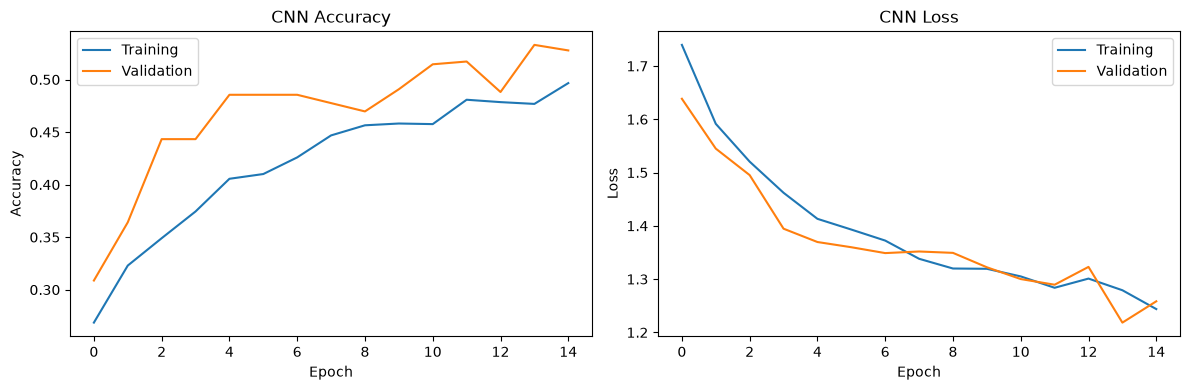

In [26]:
#Plot training and validation performance
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

CNN test accuracy: 0.4921

CNN classification report:

              precision    recall  f1-score   support

   cardboard       0.90      0.58      0.71        60
       glass       0.56      0.26      0.36        76
       metal       0.45      0.47      0.46        62
       paper       0.63      0.53      0.57        89
     plastic       0.59      0.55      0.57        73
       trash       0.16      0.80      0.27        20

    accuracy                           0.49       380
   macro avg       0.55      0.53      0.49       380
weighted avg       0.60      0.49      0.52       380



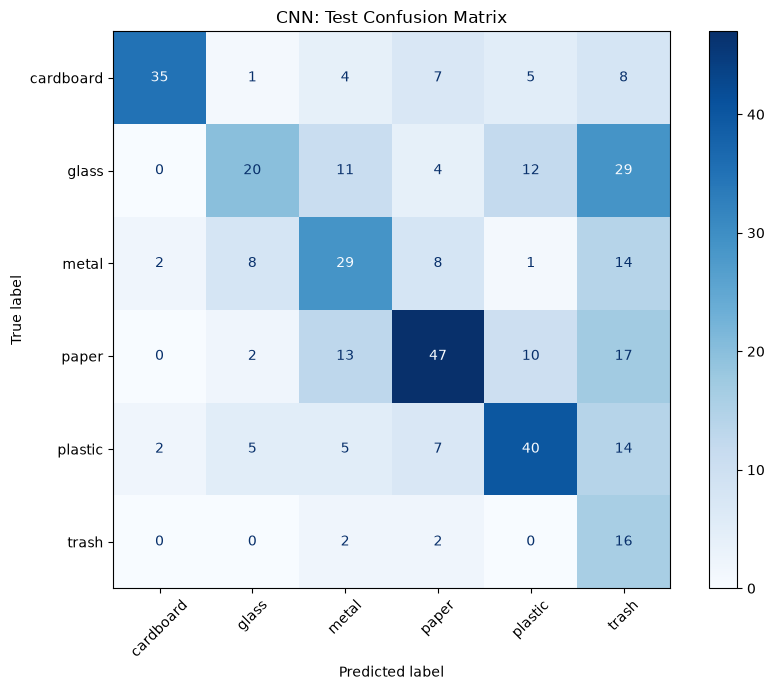

In [27]:
#Evaluate the CNN on the held-out test set
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

cnn_probabilities = cnn.predict(X_test_img, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

print(
    "CNN test accuracy:",
    round(accuracy_score(y_test_int, cnn_predictions), 4)
)

print("\nCNN classification report:\n")
print(classification_report(
    y_test_int,
    cnn_predictions,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0
))

cm_cnn = confusion_matrix(
    y_test_int,
    cnn_predictions,
    labels=list(range(len(CLASSES)))
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=CLASSES
).plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("CNN: Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
#Improve the CNN with a controlled second training stage

from tensorflow import keras

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

early_stopping_finetune = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history_finetune = cnn.fit(
    X_train_img,
    y_train_int,
    validation_data=(X_val_img, y_val_int),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[
        reduce_lr,
        early_stopping_finetune
    ],
    verbose=1
)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - accuracy: 0.4983 - loss: 1.2463 - val_accuracy: 0.4960 - val_loss: 1.3327 - learning_rate: 0.0010
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.4836 - loss: 1.2617 - val_accuracy: 0.5330 - val_loss: 1.2683 - learning_rate: 0.0010
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - accuracy: 0.4960 - loss: 1.2380 - val_accuracy: 0.5541 - val_loss: 1.2023 - learning_rate: 0.0010
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.5090 - loss: 1.2248 - val_accuracy: 0.5356 - val_loss: 1.2339 - learning_rate: 0.0010
Epoch 5/20
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5074 - loss: 1.2324
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.5062 - loss: 1.2339 - val_accuracy: 0.5251 - val_loss: 1.2910 - learning_rate: 0.0010
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.5107 - loss: 1.2279 - val_ac

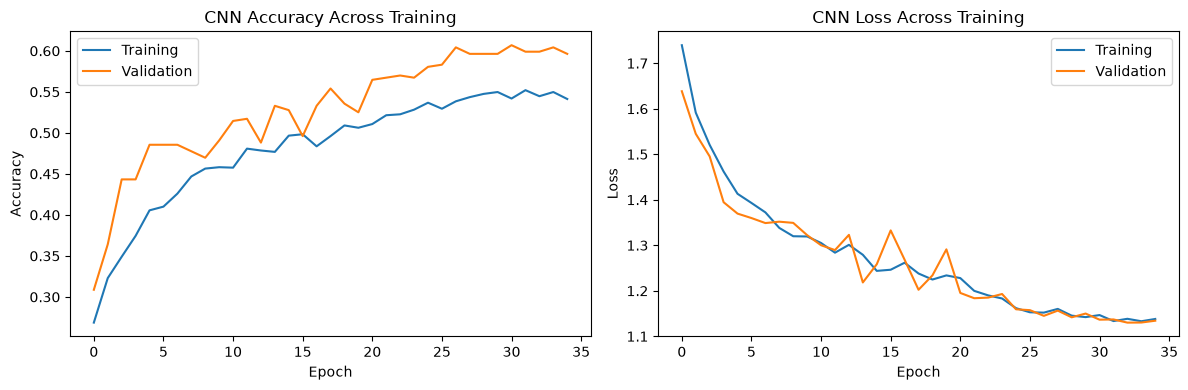

In [29]:
#updated learning curves
import matplotlib.pyplot as plt

train_accuracy = (
    history.history["accuracy"]
    + history_finetune.history["accuracy"]
)

val_accuracy = (
    history.history["val_accuracy"]
    + history_finetune.history["val_accuracy"]
)

train_loss = (
    history.history["loss"]
    + history_finetune.history["loss"]
)

val_loss = (
    history.history["val_loss"]
    + history_finetune.history["val_loss"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_accuracy, label="Training")
axes[0].plot(val_accuracy, label="Validation")
axes[0].set_title("CNN Accuracy Across Training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(train_loss, label="Training")
axes[1].plot(val_loss, label="Validation")
axes[1].set_title("CNN Loss Across Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

CNN test accuracy: 0.5474

CNN classification report:

              precision    recall  f1-score   support

   cardboard       0.87      0.65      0.74        60
       glass       0.63      0.25      0.36        76
       metal       0.48      0.50      0.49        62
       paper       0.57      0.72      0.63        89
     plastic       0.65      0.55      0.59        73
       trash       0.23      0.75      0.35        20

    accuracy                           0.55       380
   macro avg       0.57      0.57      0.53       380
weighted avg       0.61      0.55      0.55       380



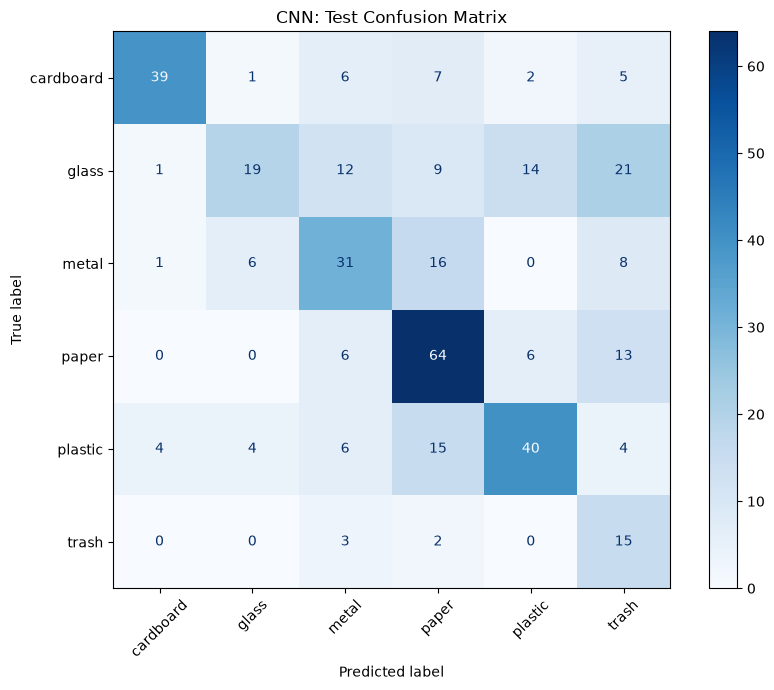

In [30]:
#Evaluate the CNN on the held-out test set
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

cnn_probabilities = cnn.predict(X_test_img, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

print(
    "CNN test accuracy:",
    round(accuracy_score(y_test_int, cnn_predictions), 4)
)

print("\nCNN classification report:\n")
print(classification_report(
    y_test_int,
    cnn_predictions,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0
))

cm_cnn = confusion_matrix(
    y_test_int,
    cnn_predictions,
    labels=list(range(len(CLASSES)))
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=CLASSES
).plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("CNN: Test Confusion Matrix")
plt.tight_layout()
plt.show()

The Support Vector Machine (SVM), trained on Histogram of Oriented Gradients (HOG) features, outperformed the Convolutional Neural Network (CNN) on the TrashNet test set. The SVM achieved 62.11% accuracy and a macro-F1 score of approximately 0.60, compared with 54.74% accuracy and a macro-F1 score of approximately 0.53 for the CNN. Fine-tuning improved the CNN's test accuracy from 49.21% to 54.74%, although it did not surpass the traditional machine-learning model.

Class-level results revealed important differences between the models. The CNN achieved higher recall for the minority *trash* class (0.75 compared with 0.35 for the SVM), but its precision for this class was only 0.23, indicating frequent false-positive predictions. Conversely, the SVM performed substantially better on glass, achieving recall of 0.66 compared with 0.25 for the CNN. These findings demonstrate that model performance depends on the target class and the cost of different classification errors. The results also suggest that a more complex deep-learning architecture does not necessarily outperform a traditional model on a relatively small dataset.

The findings should be interpreted cautiously because the dataset is relatively small, the classes are imbalanced, and the evaluation reflects only this dataset and experimental setup. Further validation on images collected in real recycling environments would be necessary before deployment.

In [32]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Explicitly build the CNN by passing a sample image through it
_ = cnn(tf.zeros((1, 96, 96, 3)), training=False)

# Find the final convolutional layer
last_conv_layer = next(
    layer for layer in reversed(cnn.layers)
    if isinstance(layer, tf.keras.layers.Conv2D)
)

print("Convolutional layer:", last_conv_layer.name)

# Create a model that returns the convolutional features and predictions
grad_model = tf.keras.Model(
    inputs=cnn.inputs,
    outputs=[
        cnn.get_layer(last_conv_layer.name).output,
        cnn.layers[-1].output
    ]
)

Convolutional layer: conv2d_2


In [34]:
print("Grad-CAM model ready:", grad_model)

Grad-CAM model ready: <Functional name=functional_1, built=True>


In [36]:
def make_gradcam_heatmap(image, pred_index=None):
    image_tensor = tf.convert_to_tensor(
        image[np.newaxis, ...], dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_tensor, training=False
        )

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    gradients = tape.gradient(class_score, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), int(tf.argmax(predictions[0]))


def show_gradcam(image, true_label):
    heatmap, predicted_index = make_gradcam_heatmap(image)

    predicted_label = CLASSES[predicted_index]

    heatmap_image = Image.fromarray(
        np.uint8(255 * heatmap)
    ).resize((image.shape[1], image.shape[0]))

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(f"Original — actual: {true_label}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(image)
    plt.imshow(np.asarray(heatmap_image), alpha=0.45)
    plt.title(f"Grad-CAM — predicted: {predicted_label}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Actual class:", true_label)
    print("Predicted class:", predicted_label)

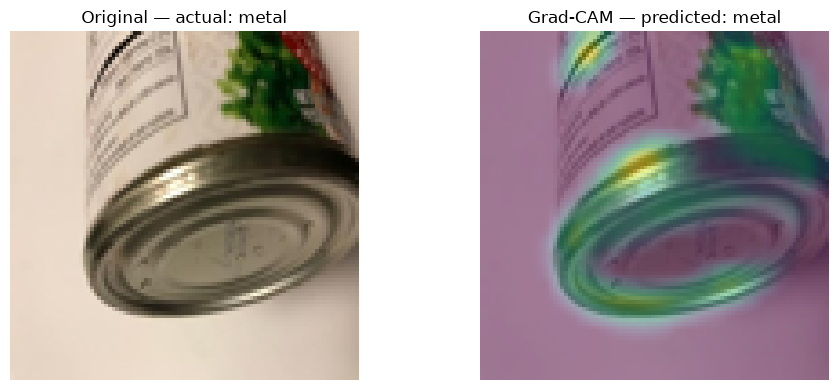

Actual class: metal
Predicted class: metal


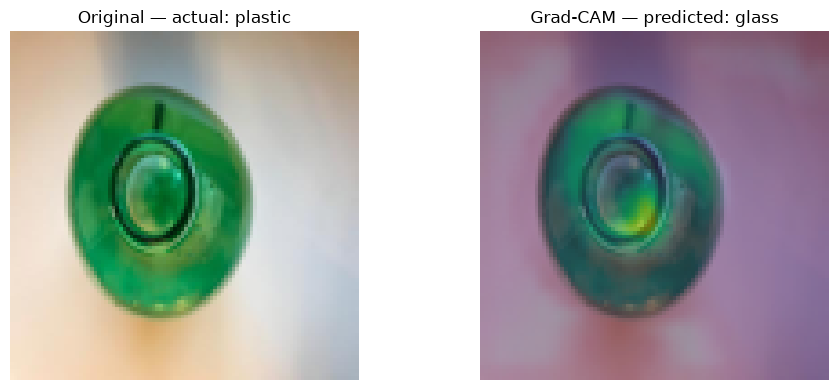

Actual class: plastic
Predicted class: glass


In [37]:
# Generate Grad-CAM for one correct prediction
if len(correct_indices) > 0:
    i = correct_indices[0]
    show_gradcam(X_test_img[i], y_test[i])

# Generate Grad-CAM for one incorrect prediction
if len(wrong_indices) > 0:
    i = wrong_indices[0]
    show_gradcam(X_test_img[i], y_test[i])

## EXPLAINABILITY 
Grad-CAM was used to investigate the visual regions influencing the CNN's predictions. In a correctly classified metal-can image, the heatmap highlighted regions around the metallic rim and lower circular structure. This suggests that features associated with the object's contours and surface appearance contributed to the prediction. Nevertheless, the visualisation does not prove that the CNN relied exclusively on meaningful material characteristics.

In a misclassified example, an image of a plastic container was predicted as glass. Grad-CAM highlighted the central and lower regions of the container, particularly around its base. The error may reflect the visual similarity between glass and plastic containers, including shared shapes, colours and reflective patterns. This demonstrates a limitation of image-based material classification: visual appearance does not always provide sufficient evidence to distinguish materials reliably.

Grad-CAM improves interpretability by showing regions associated with a prediction, but it does not establish causation or guarantee that a prediction is correct. The findings support the need for additional testing using diverse images, different lighting conditions and real-world waste items before deploying the CNN in an automated recycling system.

# Comparative Evaluation of the Models

In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Generate final predictions
svm_test_predictions = best_svm.predict(X_test_hog)

cnn_test_probabilities = cnn.predict(X_test_img, verbose=0)
cnn_test_predictions = np.array([
    CLASSES[i] for i in np.argmax(cnn_test_probabilities, axis=1)
])

# Summarise metrics for each model
comparison_rows = []

for model_name, y_pred in [
    ("HOG + SVM", svm_test_predictions),
    ("CNN", cnn_test_predictions)
]:
    report = classification_report(
        y_test,
        y_pred,
        labels=CLASSES,
        output_dict=True,
        zero_division=0
    )

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison_rows)

# Display the results without requiring jinja2
comparison_df.round(3)






,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,HOG + SVM,0.621,0.646,0.581,0.598
1,CNN,0.547,0.571,0.570,0.528


In [41]:

class_comparison_rows = []

for model_name, y_pred in [
    ("HOG + SVM", svm_test_predictions),
    ("CNN", cnn_test_predictions)
]:
    report = classification_report(
        y_test,
        y_pred,
        labels=CLASSES,
        output_dict=True,
        zero_division=0
    )

    for class_name in CLASSES:
        class_comparison_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

class_comparison_df = pd.DataFrame(class_comparison_rows)

# Display the class-level comparison, rounded to 2 decimal places
class_comparison_df.round(2)


,Model,Class,Precision,Recall,F1-score,Support
0,HOG + SVM,cardboard,0.66,0.62,0.64,60.0
1,HOG + SVM,glass,0.57,0.66,0.61,76.0
2,HOG + SVM,metal,0.59,0.53,0.56,62.0
3,HOG + SVM,paper,0.63,0.75,0.69,89.0
4,HOG + SVM,plastic,0.65,0.58,0.61,73.0
5,HOG + SVM,trash,0.78,0.35,0.48,20.0
6,CNN,cardboard,0.87,0.65,0.74,60.0
7,CNN,glass,0.63,0.25,0.36,76.0
8,CNN,metal,0.48,0.50,0.49,62.0
9,CNN,paper,0.57,0.72,0.63,89.0


The comparative evaluation indicates that the HOG-based SVM achieved stronger overall performance than the CNN on the held-out test set. However, performance varied by waste category. The CNN achieved higher recall for the minority trash class but had lower precision, indicating that many predictions of trash were incorrect. The SVM performed better at identifying glass. These differences demonstrate why accuracy should be considered alongside macro-averaged metrics and class-level performance when evaluating waste-classification systems.

# Robustness Analysis: Brightness Perturbation

In [44]:

from PIL import Image, ImageEnhance
from skimage.feature import hog
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

def adjust_brightness(images, factor=1.25):
    adjusted = []

    for image in images:
        pil_image = Image.fromarray(image.astype(np.uint8))
        brighter = ImageEnhance.Brightness(pil_image).enhance(factor)
        adjusted.append(np.asarray(brighter))

    return np.asarray(adjusted)

# Create a brighter copy of the test images
X_test_bright = adjust_brightness(X_test_img, factor=1.25)

# Extract HOG features using the same settings as training
X_test_bright_hog = extract_hog_features(X_test_bright)

# Evaluate both trained models on the altered images
svm_bright_predictions = best_svm.predict(X_test_bright_hog)

cnn_bright_probabilities = cnn.predict(X_test_bright, verbose=0)
cnn_bright_predictions = np.array([
    CLASSES[i] for i in np.argmax(cnn_bright_probabilities, axis=1)
])

robustness_results = []

for model_name, predictions in [
    ("HOG + SVM", svm_bright_predictions),
    ("CNN", cnn_bright_predictions)
]:
    robustness_results.append({
        "Model": model_name,
        "Condition": "Brighter images (+25%)",
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, labels=CLASSES,
            average="macro", zero_division=0
        )
    })

robustness_df = pd.DataFrame(robustness_results)



Extracting HOG:   0%|          | 0/380 [00:00<?, ?it/s]

In [45]:

robustness_df.round(3)


,Model,Condition,Accuracy,Macro F1
0,HOG + SVM,Brighter images (+25%),0.582,0.532
1,CNN,Brighter images (+25%),0.489,0.456


## Robustness Analysis: Brightness Perturbation

The robustness experiment evaluated both models using test images whose brightness was increased by 25%. The HOG-based SVM's accuracy decreased from 62.1% to 58.2%, while its macro-F1 score declined from approximately 0.598 to 0.532. The CNN's accuracy decreased from 54.7% to 48.9%, and its macro-F1 score fell from approximately 0.528 to 0.456.

These results indicate that both models were sensitive to the brightness perturbation, with the CNN experiencing a larger reduction in both metrics. The SVM therefore demonstrated greater stability under this particular test condition. However, this single experiment does not establish general robustness across all lighting conditions, camera angles, backgrounds or waste environments. Further evaluation using varied real-world images would be necessary before deployment.

# Ethical Considerations and Deployment Recommendations

### Ethical Considerations

**Reliability and potential harm:** Incorrect classification may cause recyclable materials to be discarded or contaminate recycling streams. The observed errors, particularly the CNN's low precision for the trash class and low recall for glass, could have operational consequences.

**Fairness:** Performance varies across the six waste classes. These are class-level disparities and should not be interpreted as demographic bias because the dataset does not provide demographic attributes for analysis.

**Explainability and accountability:** Grad-CAM provides visual insights into regions influencing CNN predictions. However, highlighted regions do not guarantee that the model has learned meaningful material characteristics or that its predictions are correct. Human review remains important.

**Privacy:** Images collected for future training or deployment should be handled responsibly. Collection procedures should minimise unnecessary capture of people, addresses and other identifying information.

### Deployment Recommendations

Neither model should be deployed as a fully autonomous recycling classifier based solely on these results. The SVM is the stronger overall candidate in this experiment, but its test accuracy of approximately 62% is insufficient to justify unsupervised operational use. A pilot system should retain human oversight, be evaluated on images from real recycling environments, monitor class-specific errors and be tested under diverse lighting and background conditions. Future work should also investigate more representative training data and additional model configurations.


# CONCLUSION
This study compared a traditional machine-learning approach, an SVM trained on HOG features, with a CNN for six-class waste image classification using TrashNet. The SVM achieved higher test accuracy and macro-F1 than the CNN, demonstrating that a more complex deep-learning model does not necessarily outperform traditional machine learning on a relatively small dataset.

Class-level evaluation showed that the models had different strengths and weaknesses. The CNN achieved higher recall for trash, whereas the SVM performed better on glass and achieved stronger overall results. Grad-CAM provided additional insight into the CNN's predictions, including an example in which plastic was misclassified as glass. The brightness experiment further demonstrated that both models were sensitive to altered image conditions.

Overall, the SVM was the stronger model under the experimental conditions, but neither model is ready for unsupervised deployment. Larger and more diverse datasets, stronger validation, further robustness testing and human oversight are recommended before practical use.

# References

Barocas, S., Hardt, M. and Narayanan, A. (2023) *Fairness and Machine Learning: Limitations and Opportunities*. Cambridge, MA: MIT Press. Available at: https://fairmlbook.org/ (Accessed: 11 October 2026).

Cortes, C. and Vapnik, V. (1995) ‘Support-vector networks’, *Machine Learning*, 20, pp. 273–297. Available at: https://doi.org/10.1007/BF00994018.

Dalal, N. and Triggs, B. (2005) ‘Histograms of oriented gradients for human detection’, in *Proceedings of the IEEE Computer Society Conference on Computer Vision and Pattern Recognition (CVPR)*. Vol. 1, pp. 886–893. Available at: https://doi.org/10.1109/CVPR.2005.177.

LeCun, Y., Bengio, Y. and Hinton, G. (2015) ‘Deep learning’, *Nature*, 521, pp. 436–444. Available at: https://doi.org/10.1038/nature14539.

National Institute of Standards and Technology (NIST) (2023) Artificial Intelligence Risk Management Framework (AI RMF 1.0). NIST AI 100-1. Gaithersburg, MD: NIST. Available at: https://doi.org/10.6028/NIST.AI.100-1 (Accessed: 11 October 2026).

Selvaraju, R.R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. and Batra, D. (2017) ‘Grad-CAM: Visual explanations from deep networks via gradient-based localization’, in Proceedings of the IEEE International Conference on Computer Vision (ICCV), pp. 618–626. Available at: https://doi.org/10.1109/ICCV.2017.74.

Sokolova, M. and Lapalme, G. (2009) ‘A systematic analysis of performance measures for classification tasks’, Information Processing & Management, 45(4), pp. 427–437. Available at: https://doi.org/10.1016/j.ipm.2009.03.002.

Thung, G. and Yang, M. (2016) Classification of Trash for Recyclability Status. Stanford University, CS229 Machine Learning course project report. Available at: https://cs229.stanford.edu/proj2016/report/ThungYang-ClassificationOfTrashForRecyclabilityStatus-report.pdf (Accessed: 11 October 2026).

Thung, G. (n.d.) TrashNet dataset. Hugging Face. Available at: https://huggingface.co/datasets/garythung/trashnet (Accessed: 11 October 2026).
